# Desafío - Identificación de escenarios naturales del mundo
**Módulo 6 - Unidad 3: Procesamiento y redes recurrentes (Parte I) - Redes Neuronales Convolucionales**
Rafael Riesco - G122

Clasificación de imágenes en seis clases (buildings, forest, glacier, mountain, sea, street) mediante una red Fully Connected y dos redes convolucionales (CNN).

**Ejecución:** notebook preparado para **Google Colab con GPU** (Entorno de ejecución → Cambiar tipo de entorno → GPU). Los cinco archivos `.npy` del curso deben estar en una carpeta de Google Drive (ver celda de configuración). Los datos no se incluyen en el repositorio por su tamaño.

## 0. Configuración del entorno
Se verifica la GPU, se monta Google Drive y se copian los datos al disco local de Colab (la lectura es más rápida que directamente desde Drive).

**Ajustar `CARPETA_DRIVE`** a la ruta donde se subieron los archivos `.npy`.

In [ ]:
import os, shutil, glob

CARPETA_DRIVE = '/content/drive/MyDrive/desafio_cnn'   # <-- ajustar si es necesario
CARPETA_LOCAL = '/content/datos'

from google.colab import drive
drive.mount('/content/drive')

os.makedirs(CARPETA_LOCAL, exist_ok=True)
for f in glob.glob(os.path.join(CARPETA_DRIVE, '*.npy')):
    destino = os.path.join(CARPETA_LOCAL, os.path.basename(f))
    if not os.path.exists(destino):
        shutil.copy(f, destino)
print('Archivos disponibles:', sorted(os.listdir(CARPETA_LOCAL)))

Mounted at /content/drive
Archivos disponibles: ['cnn_pred_X.npy', 'cnn_test_X.npy', 'cnn_test_y.npy', 'cnn_train_X.npy', 'cnn_train_y.npy']


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__, '| GPU disponible:', gpus)

# Precisión mixta: acelera el entrenamiento en GPU (cálculos en float16, pesos en float32)
if gpus:
    keras.mixed_precision.set_global_policy('mixed_float16')

TensorFlow: 2.21.0 | GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Importación, conteo por clase, visualización y codificación One-Hot
Los archivos están serializados con pickle, por lo que se cargan con `np.load(..., allow_pickle=True)`. El conjunto de predicción (`cnn_pred_X.npy`) no trae etiquetas.

In [ ]:
def cargar(nombre):
    return np.load(os.path.join(CARPETA_LOCAL, nombre), allow_pickle=True)

X_train = cargar('cnn_train_X.npy')
y_train = cargar('cnn_train_y.npy').reshape(-1)
X_test = cargar('cnn_test_X.npy')
y_test = cargar('cnn_test_y.npy').reshape(-1)
X_pred = cargar('cnn_pred_X.npy')

# Si las imágenes vienen como arreglo de objetos, se apilan en un único tensor
X_train, X_test, X_pred = [np.stack(x) if x.dtype == object else x for x in (X_train, X_test, X_pred)]

CLASES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
def a_nombre(y):
    y = np.asarray(y)
    if np.issubdtype(y.dtype, np.number):
        return np.array([CLASES[int(v)] for v in y])
    return y.astype(str)

y_train, y_test = a_nombre(y_train), a_nombre(y_test)

for nombre, X in [('Train', X_train), ('Test', X_test), ('Predicción', X_pred)]:
    print(f'{nombre}: {X.shape} | dtype: {X.dtype} | rango: [{X.min()}, {X.max()}]')

conteo = pd.DataFrame({
    'train': pd.Series(y_train).value_counts(),
    'test': pd.Series(y_test).value_counts()
}).sort_index()
conteo.loc['TOTAL'] = conteo.sum()
print('\nCantidad de imágenes por categoría:')
print(conteo)
print(f'\nConjunto de predicción: {len(X_pred)} imágenes sin etiqueta')

Train: (14034, 32, 32, 3) | dtype: float64 | rango: [0.0, 1.0]
Test: (3000, 32, 32, 3) | dtype: float64 | rango: [0.0, 1.0]
Predicción: (7301, 32, 32, 3) | dtype: float64 | rango: [0.0, 1.0]

Cantidad de imágenes por categoría:
           train  test
buildings   2191   437
forest      2271   474
glacier     2404   553
mountain    2512   525
sea         2274   510
street      2382   501
TOTAL      14034  3000

Conjunto de predicción: 7301 imágenes sin etiqueta


**Observación:** el entrenamiento tiene 14.034 imágenes, el test 3.000 y el conjunto de predicción 7.301 (sin etiquetas). Todas son de 32×32 píxeles RGB y vienen ya normalizadas en [0, 1]. Las seis clases están razonablemente balanceadas en ambos conjuntos (entre 2.191 y 2.512 imágenes por clase en entrenamiento), por lo que el accuracy es una métrica adecuada, complementada con F1 macro.

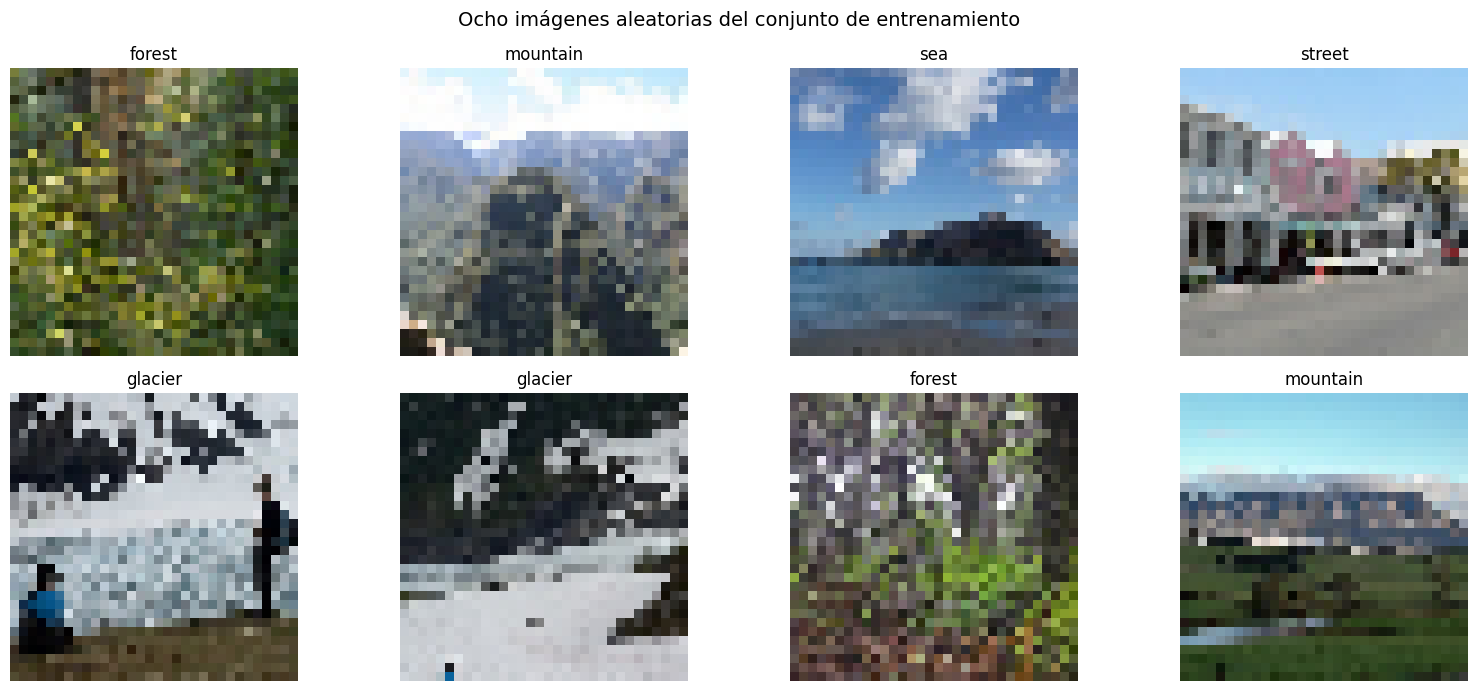

In [ ]:
def mostrar_imagenes(X, etiquetas, titulo, n=8, semilla=42):
    rng = np.random.default_rng(semilla)
    idx = rng.choice(len(X), size=n, replace=False)
    fig, axes = plt.subplots(2, n // 2, figsize=(16, 7))
    for ax, i in zip(axes.flat, idx):
        img = X[i]
        ax.imshow(img.astype('uint8') if img.max() > 1 else img)
        ax.set_title(etiquetas[i], fontsize=12)
        ax.axis('off')
    plt.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()

mostrar_imagenes(X_train, y_train, 'Ocho imágenes aleatorias del conjunto de entrenamiento')

In [ ]:
# Normalización de píxeles a [0, 1]: se aplica DENTRO de cada modelo con una capa Rescaling.
# Así las imágenes se mantienen en memoria como uint8 (4 veces menos RAM que float32).
ESCALA = 1 / 255 if X_train.max() > 1 else 1.0
print('Factor de escala de los píxeles:', ESCALA)

# Codificación One-Hot de las etiquetas
ohe = OneHotEncoder(sparse_output=False)
y_train_oh = ohe.fit_transform(y_train.reshape(-1, 1))
y_test_oh = ohe.transform(y_test.reshape(-1, 1))
NOMBRES = list(ohe.categories_[0])
print('Orden de las columnas One-Hot:', NOMBRES)
print('y_train_oh:', y_train_oh.shape, '| y_test_oh:', y_test_oh.shape)
print('Ejemplo:', y_train[0], '->', y_train_oh[0])

# Separación estratificada de validación (15% del entrenamiento) para controlar el entrenamiento
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train_oh, test_size=0.15,
                                            random_state=42, stratify=y_train)
print('Entrenamiento:', X_tr.shape, '| Validación:', X_val.shape, '| Test:', X_test.shape)

Factor de escala de los píxeles: 1.0
Orden de las columnas One-Hot: [np.str_('buildings'), np.str_('forest'), np.str_('glacier'), np.str_('mountain'), np.str_('sea'), np.str_('street')]
y_train_oh: (14034, 6) | y_test_oh: (3000, 6)
Ejemplo: forest -> [0. 1. 0. 0. 0. 0.]
Entrenamiento: (11928, 32, 32, 3) | Validación: (2106, 32, 32, 3) | Test: (3000, 32, 32, 3)


**Decisiones de preparación:**
- Las imágenes vienen como arreglos de 32×32×3 en `float64`, ya normalizadas en el rango [0, 1]. El código detecta el rango y fija el factor de escala en 1.0 (si los píxeles vinieran entre 0 y 255, la capa `Rescaling` al inicio de cada red los llevaría a [0, 1]). Trabajar con valores en [0, 1] estabiliza el descenso del gradiente.
- Las etiquetas se codifican con `OneHotEncoder`: una columna por clase, compatible con la salida **softmax** de 6 neuronas y la pérdida **categorical crossentropy**.
- Se reserva un 15% estratificado del entrenamiento como **validación**, para monitorear el entrenamiento sin usar el conjunto de test. Se usa `train_test_split` y no `validation_split` de Keras porque este último toma las últimas filas, que podrían estar ordenadas por clase.

In [ ]:
# Funciones auxiliares de evaluación y gráficos
def graficar_historia(h, titulo, val_label='validación'):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    ep = range(1, len(h.history['loss']) + 1)
    axes[0].plot(ep, h.history['loss'], marker='o', label='train')
    axes[0].plot(ep, h.history['val_loss'], marker='o', label=val_label)
    axes[0].set_title('Pérdida (categorical crossentropy)'); axes[0].set_xlabel('Época'); axes[0].legend()
    axes[1].plot(ep, h.history['accuracy'], marker='o', label='train')
    axes[1].plot(ep, h.history['val_accuracy'], marker='o', label=val_label)
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Época'); axes[1].legend()
    plt.suptitle(titulo, fontsize=13); plt.tight_layout(); plt.show()

resultados = []
def evaluar(modelo, nombre):
    proba = modelo.predict(X_test, verbose=0)
    pred = np.array(NOMBRES)[proba.argmax(axis=1)]
    acc = accuracy_score(y_test, pred)
    f1m = f1_score(y_test, pred, average='macro')
    print(f'===== {nombre} =====')
    print(f'Accuracy test: {acc:.4f} | F1 macro test: {f1m:.4f}')
    print(classification_report(y_test, pred, digits=3))
    cm = confusion_matrix(y_test, pred, labels=NOMBRES)
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=NOMBRES, yticklabels=NOMBRES)
    plt.xlabel('Predicho'); plt.ylabel('Real'); plt.title(f'Matriz de confusión (test) - {nombre}')
    plt.show()
    resultados.append({'modelo': nombre, 'parametros': modelo.count_params(),
                       'accuracy_test': acc, 'f1_macro_test': f1m})
    return pred, cm

def capa_salida():
    # dtype float32 en la salida para estabilidad numérica con precisión mixta
    return layers.Dense(len(NOMBRES), activation='softmax', dtype='float32')

parada = lambda pac: keras.callbacks.EarlyStopping(monitor='val_loss', patience=pac,
                                                   restore_best_weights=True)

## 2. Red neuronal multicapa Fully Connected (5 capas ocultas)
Una red densa no "ve" la estructura espacial de la imagen: `Flatten` convierte cada imagen en un vector y cada píxel se trata como una variable independiente. Es la línea base contra la que se comparan las CNN.

**Arquitectura:** Flatten → 5 capas densas ocultas (256, 128, 64, 64, 32) con ReLU e inicialización He → salida softmax de 6 neuronas. Se agrega Dropout para limitar el sobreajuste (la primera capa densa concentra millones de parámetros). Optimizador Adam, pérdida categorical crossentropy y parada temprana sobre la pérdida de validación.

Model: "fully_connected"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 834,278 (3.18 MB)

 Trainable params: 834,278 (3.18 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
187/187 - 13s - 72ms/step - accuracy: 0.2757 - loss: 1.7068 - val_accuracy: 0.4283 - val_loss: 1.5114
Epoch 2/30
187/187 - 1s - 4ms/step - accuracy: 0.4043 - loss: 1.5068 - val_accuracy: 0.4824 - val_loss: 1.3888
Epoch 3/30
187/187 - 1s - 4ms/step - accuracy: 0.4490 - loss: 1.4137 - val_accuracy: 0.5038 - val_loss: 1.3304
Epoch 4/30
187/187 - 1s - 4ms/step - accuracy: 0.4668 - loss: 1.3671 - val_accuracy: 0.4905 - val_loss: 1.3180
Epoch 5/30
187/187 - 1s - 7ms/step - accuracy: 0.4791 - loss: 1.3331 - val_accuracy: 0.5185 - val_loss: 1.2780
Epoch 6/30
187/187 - 1s - 4ms/step - accuracy: 0.4935 - loss: 1.3055 - val_accuracy: 0.5237 - val_loss: 1.2571
Epoch 7/30
187/187 - 1s - 4ms/step - accuracy: 0.5048 - loss: 1.2724 - val_accuracy: 0.5342 - val_loss: 1.2347
Epoch 8/30
187/187 - 1s - 4ms/step - accuracy: 0.5169 - loss: 1.2515 - val_accuracy: 0.5361 - val_loss: 1.2170
Epoch 9/30
187/187 - 1s - 4ms/step - accuracy: 0.5212 - loss: 1.2379 - val_accuracy: 0.5437 - val_loss: 1.1991

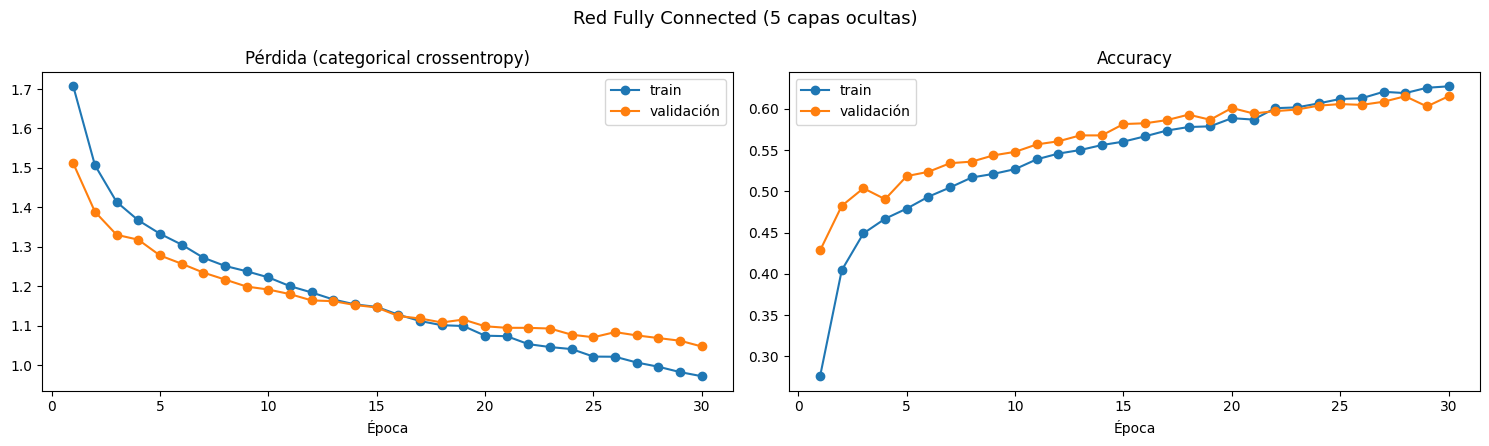

===== Fully Connected =====
Accuracy test: 0.5917 | F1 macro test: 0.5848
              precision    recall  f1-score   support

   buildings      0.440     0.403     0.421       437
      forest      0.771     0.745     0.758       474
     glacier      0.600     0.599     0.599       553
    mountain      0.635     0.636     0.636       525
         sea      0.483     0.396     0.435       510
      street      0.587     0.756     0.661       501

    accuracy                          0.592      3000
   macro avg      0.586     0.589     0.585      3000
weighted avg      0.588     0.592     0.587      3000



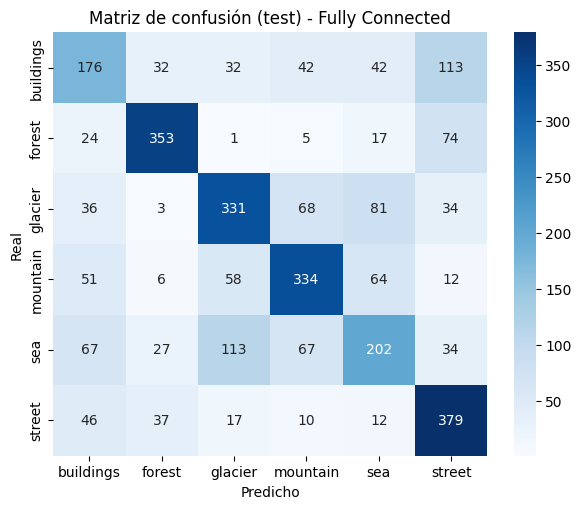

In [ ]:
keras.utils.set_random_seed(42)
modelo_fc = keras.Sequential([
    keras.Input(shape=X_train.shape[1:]),
    layers.Rescaling(ESCALA),
    layers.Flatten(),
    layers.Dense(256, activation='relu', kernel_initializer='he_normal'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal'),
    layers.Dense(64, activation='relu', kernel_initializer='he_normal'),
    layers.Dense(32, activation='relu', kernel_initializer='he_normal'),
    capa_salida()
], name='fully_connected')
modelo_fc.compile(optimizer=keras.optimizers.Adam(1e-4), loss='categorical_crossentropy',
                  metrics=['accuracy'])
modelo_fc.summary()

inicio = time.time()
hist_fc = modelo_fc.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=30, batch_size=64,
                        callbacks=[parada(5)], verbose=2)
print(f'Tiempo de entrenamiento: {(time.time() - inicio) / 60:.1f} min')
graficar_historia(hist_fc, 'Red Fully Connected (5 capas ocultas)')
pred_fc, cm_fc = evaluar(modelo_fc, 'Fully Connected')

**Observación:** la red Fully Connected (834.278 parámetros) obtiene **59.2% de accuracy en test** (F1 macro 0.585), muy superior al azar (16.7% con seis clases), pero limitada: al aplanar la imagen pierde la estructura espacial y debe aprender cada patrón en cada posición por separado. Las clases más difíciles son buildings y sea (recall ~0.40) y la mejor es forest (0.745). La pérdida de validación seguía descendiendo en la época 30, por lo que el modelo no había convergido completamente.

## 3. Red convolucional con 3 capas convolucionales y 2 densas (entre 3 y 8 millones de parámetros, 25 épocas)
**Arquitectura** (patrón de la guía: convolución → pooling, repetido, y luego capas densas):
- 3 capas **Conv2D (3×3, ReLU, padding 'same')** con 64, 128 y 256 filtros: extraen desde bordes simples hasta patrones más abstractos. El padding 'same' conserva el tamaño del mapa en cada convolución.
- 2 operaciones **MaxPooling2D (2×2)**, después de la primera y la segunda convolución: con imágenes de 32×32, el mapa final queda de 8×8×256.
- **Flatten** (16.384 valores) → 2 capas **densas** (256 y 128, ReLU) → salida softmax.
- La primera capa densa concentra ~4.2 millones de parámetros, para un total de 4.599.046, dentro del intervalo exigido.

Model: "cnn_3conv_2densas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,599,046 (17.54 MB)

 Trainable params: 4,599,046 (17.54 MB)

 Non-trainable params: 0 (0.00 B)

Parámetros: 4,599,046 -> dentro de [3MM, 8MM]: True
Epoch 1/25
220/220 - 22s - 102ms/step - accuracy: 0.5914 - loss: 1.0442 - val_accuracy: 0.6693 - val_loss: 0.8593
Epoch 2/25
220/220 - 1s - 6ms/step - accuracy: 0.7310 - loss: 0.7298 - val_accuracy: 0.7383 - val_loss: 0.7123
Epoch 3/25
220/220 - 1s - 6ms/step - accuracy: 0.7827 - loss: 0.5981 - val_accuracy: 0.7480 - val_loss: 0.7190
Epoch 4/25
220/220 - 1s - 6ms/step - accuracy: 0.8109 - loss: 0.5189 - val_accuracy: 0.7490 - val_loss: 0.7196
Epoch 5/25
220/220 - 1s - 6ms/step - accuracy: 0.8396 - loss: 0.4397 - val_accuracy: 0.7873 - val_loss: 0.6428
Epoch 6/25
220/220 - 1s - 6ms/step - accuracy: 0.8649 - loss: 0.3751 - val_accuracy: 0.7563 - val_loss: 0.7546
Epoch 7/25
220/220 - 1s - 6ms/step - accuracy: 0.8811 - loss: 0.3293 - val_accuracy: 0.7687 - val_loss: 0.8261
Epoch 8/25
220/220 - 1s - 6ms/step - accuracy: 0.8995 - loss: 0.2784 - val_accuracy: 0.7497 - val_loss: 0.8898
Epoch 9/25
220/220 - 1s - 6ms/step - accuracy: 0.9158 - l

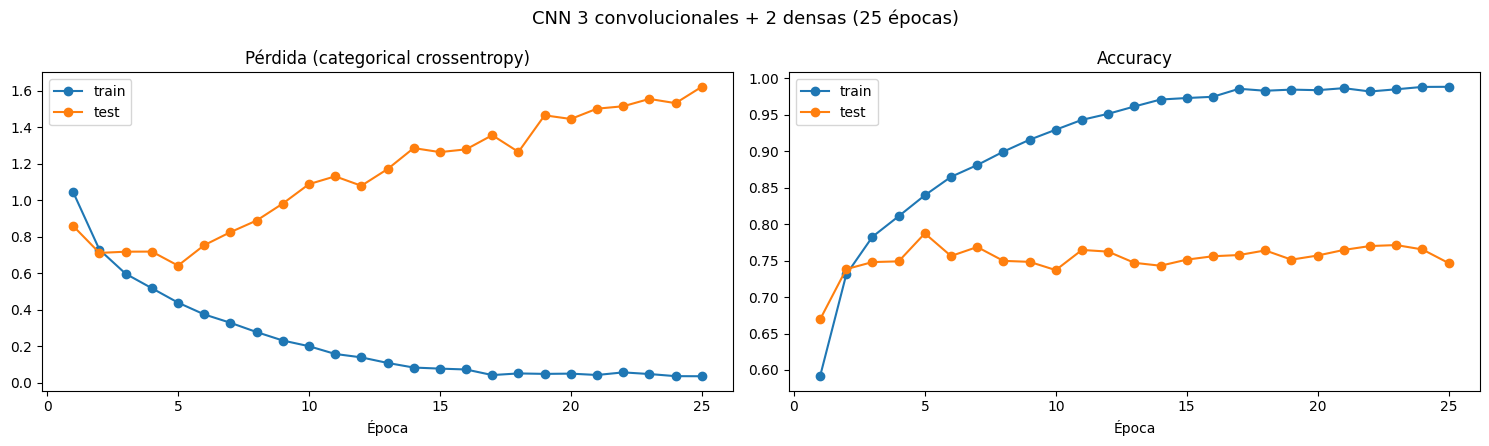

===== CNN (3 conv + 2 densas) =====
Accuracy test: 0.7467 | F1 macro test: 0.7501
              precision    recall  f1-score   support

   buildings      0.617     0.812     0.702       437
      forest      0.962     0.800     0.873       474
     glacier      0.672     0.781     0.722       553
    mountain      0.805     0.623     0.702       525
         sea      0.721     0.749     0.735       510
      street      0.808     0.729     0.766       501

    accuracy                          0.747      3000
   macro avg      0.764     0.749     0.750      3000
weighted avg      0.764     0.747     0.749      3000



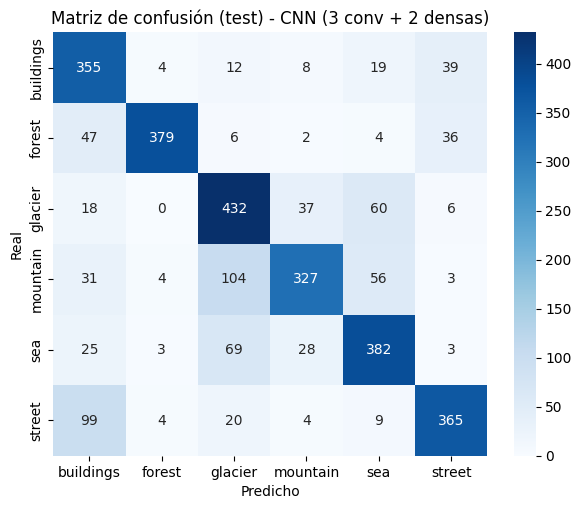

In [ ]:
keras.utils.set_random_seed(42)
modelo_cnn1 = keras.Sequential([
    keras.Input(shape=X_train.shape[1:]),
    layers.Rescaling(ESCALA),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    capa_salida()
], name='cnn_3conv_2densas')
modelo_cnn1.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy',
                    metrics=['accuracy'])
modelo_cnn1.summary()

n_param = modelo_cnn1.count_params()
print(f'Parámetros: {n_param:,} -> dentro de [3MM, 8MM]: {3e6 <= n_param <= 8e6}')
assert 3e6 <= n_param <= 8e6, 'Ajustar las neuronas de la primera capa densa para entrar en el intervalo'

inicio = time.time()
hist_cnn1 = modelo_cnn1.fit(X_train, y_train_oh, validation_data=(X_test, y_test_oh),
                            epochs=25, batch_size=64, verbose=2)
print(f'Tiempo de entrenamiento: {(time.time() - inicio) / 60:.1f} min')
graficar_historia(hist_cnn1, 'CNN 3 convolucionales + 2 densas (25 épocas)', val_label='test')
pred_cnn1, cm_cnn1 = evaluar(modelo_cnn1, 'CNN (3 conv + 2 densas)')

**Observación:** la CNN (4.599.046 parámetros) alcanza **74.7% de accuracy en test**, 15.5 puntos más que la red Fully Connected, gracias a que las convoluciones capturan la estructura espacial de las imágenes. Sin embargo, las curvas muestran un **sobreajuste marcado**: la pérdida de test es mínima en la época 5 (0.64, accuracy 78.7%) y luego crece sostenidamente hasta 1.62, mientras el accuracy de entrenamiento llega a 98.8%. Con 25 épocas fijas y sin regularización, el modelo memoriza el entrenamiento (brecha de 22 puntos). Por clase, buildings tiene baja precision (0.617: otras clases se predicen como edificios) y mountain bajo recall (0.623).

## 4. Red convolucional profunda (16 capas) para mejorar la generalización
**Arquitectura inspirada en VGG-16** (guía: filtros fijos de 3×3 y max pooling de 2×2): **13 capas convolucionales + 3 densas = 16 capas**, en 5 bloques de 32, 64, 128, 256 y 256 filtros.

**Técnicas para mejorar la generalización respecto del modelo anterior:**
- **Batch Normalization** después de cada convolución: estabiliza y acelera el entrenamiento de redes profundas (la guía advierte que las redes profundas requieren métodos que permitan entrenarlas eficientemente).
- **Data augmentation** (volteo horizontal, rotación y zoom leves), activo solo durante el entrenamiento: el modelo ve variaciones de cada imagen y no puede memorizarlas.
- **Global Average Pooling** en lugar de Flatten: reduce drásticamente los parámetros de la parte densa y con ello el sobreajuste.
- **Dropout** en las capas densas, **parada temprana** y **reducción del learning rate** cuando la pérdida de validación se estanca.

Capas convolucionales: 13 | densas: 3 | total: 16
Parámetros: 3,785,958
Epoch 1/40
187/187 - 21s - 114ms/step - accuracy: 0.4797 - loss: 1.2596 - val_accuracy: 0.4972 - val_loss: 1.9113 - learning_rate: 0.0010
Epoch 2/40
187/187 - 5s - 28ms/step - accuracy: 0.6461 - loss: 0.9838 - val_accuracy: 0.5931 - val_loss: 1.3227 - learning_rate: 0.0010
Epoch 3/40
187/187 - 5s - 28ms/step - accuracy: 0.6931 - loss: 0.8818 - val_accuracy: 0.6453 - val_loss: 1.1279 - learning_rate: 0.0010
Epoch 4/40
187/187 - 10s - 54ms/step - accuracy: 0.7249 - loss: 0.8022 - val_accuracy: 0.6610 - val_loss: 1.1655 - learning_rate: 0.0010
Epoch 5/40
187/187 - 5s - 28ms/step - accuracy: 0.7477 - loss: 0.7531 - val_accuracy: 0.7460 - val_loss: 0.8035 - learning_rate: 0.0010
Epoch 6/40
187/187 - 5s - 28ms/step - accuracy: 0.7607 - loss: 0.7177 - val_accuracy: 0.7270 - val_loss: 0.7757 - learning_rate: 0.0010
Epoch 7/40
187/187 - 5s - 29ms/step - accuracy: 0.7766 - loss: 0.6678 - val_accuracy: 0.7963 - val_loss: 0.59

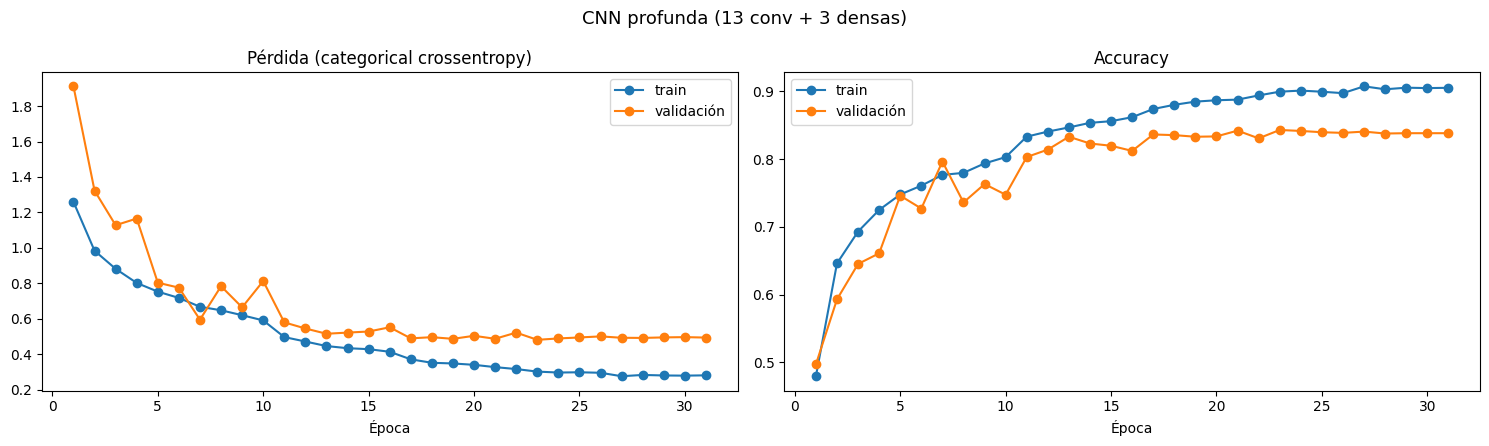

===== CNN profunda (16 capas) =====
Accuracy test: 0.8383 | F1 macro test: 0.8393
              precision    recall  f1-score   support

   buildings      0.808     0.801     0.805       437
      forest      0.950     0.954     0.952       474
     glacier      0.827     0.743     0.783       553
    mountain      0.790     0.804     0.797       525
         sea      0.814     0.865     0.838       510
      street      0.847     0.876     0.862       501

    accuracy                          0.838      3000
   macro avg      0.839     0.840     0.839      3000
weighted avg      0.838     0.838     0.838      3000



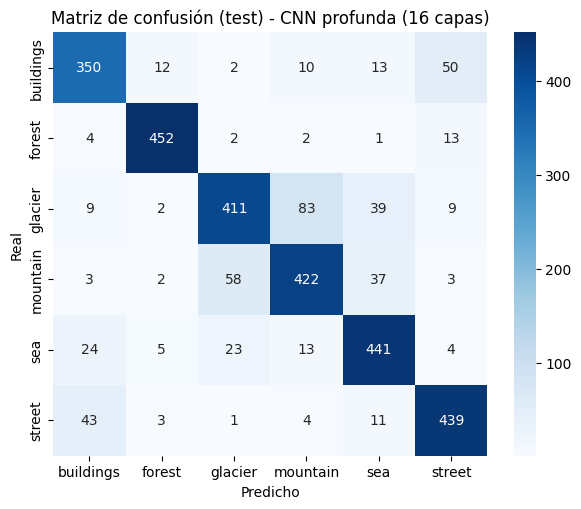

In [ ]:
def bloque(x, filtros, n_conv):
    for _ in range(n_conv):
        x = layers.Conv2D(filtros, (3, 3), padding='same', use_bias=False,
                          kernel_initializer='he_normal')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    return layers.MaxPooling2D((2, 2))(x)

keras.utils.set_random_seed(42)
entrada = keras.Input(shape=X_train.shape[1:])
x = layers.Rescaling(ESCALA)(entrada)
x = layers.RandomFlip('horizontal')(x)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomZoom(0.1)(x)
for filtros, n_conv in [(32, 2), (64, 2), (128, 3), (256, 3), (256, 3)]:
    x = bloque(x, filtros, n_conv)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
salida = capa_salida()(x)
modelo_cnn2 = keras.Model(entrada, salida, name='cnn_profunda_16_capas')

n_conv = sum(isinstance(l, layers.Conv2D) for l in modelo_cnn2.layers)
n_dense = sum(isinstance(l, layers.Dense) for l in modelo_cnn2.layers)
print(f'Capas convolucionales: {n_conv} | densas: {n_dense} | total: {n_conv + n_dense}')
print(f'Parámetros: {modelo_cnn2.count_params():,}')

modelo_cnn2.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy',
                    metrics=['accuracy'])
reducir_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-6)

inicio = time.time()
hist_cnn2 = modelo_cnn2.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=40, batch_size=64,
                            callbacks=[parada(8), reducir_lr], verbose=2)
print(f'Tiempo de entrenamiento: {(time.time() - inicio) / 60:.1f} min')
graficar_historia(hist_cnn2, 'CNN profunda (13 conv + 3 densas)')
pred_cnn2, cm_cnn2 = evaluar(modelo_cnn2, 'CNN profunda (16 capas)')

**Observación:** la red de 16 capas (13 convolucionales + 3 densas) alcanza **83.8% de accuracy en test** (F1 macro 0.839), 9.2 puntos más que la CNN anterior. La parada temprana detuvo el entrenamiento en la época 31, restaurando los pesos de la época 23 (mejor pérdida de validación, 0.481), y el learning rate se redujo cuatro veces al estancarse la validación. Las curvas de entrenamiento y validación se mantienen cercanas, sin el sobreajuste del modelo anterior. Todas las clases superan 0.74 de recall.

### Comparación de modelos y clase con más errores
La **brecha entre accuracy de entrenamiento y de test** mide la capacidad de generalización: cuanto menor, mejor generaliza el modelo.

In [ ]:
def acc_train(modelo, X, y_oh):
    return modelo.evaluate(X, y_oh, verbose=0, batch_size=128)[1]

modelos_por_nombre = {
    'Fully Connected': modelo_fc,
    'CNN (3 conv + 2 densas)': modelo_cnn1,
    'CNN profunda (16 capas)': modelo_cnn2
}
tabla = pd.DataFrame(resultados).drop_duplicates('modelo', keep='last').set_index('modelo')
tabla['accuracy_train'] = [acc_train(modelos_por_nombre[n], X_tr, y_tr) for n in tabla.index]
tabla['brecha_train_test'] = tabla['accuracy_train'] - tabla['accuracy_test']
print(tabla.round(4).to_string())

# Errores por clase del mejor modelo (CNN profunda) en test
real = pd.Series(y_test)
errores = pd.DataFrame({
    'imagenes': real.value_counts(),
    'errores': real[pred_cnn2 != y_test].value_counts()
}).fillna(0).astype(int)
errores['tasa_error'] = (errores['errores'] / errores['imagenes']).round(3)
print('\nErrores por clase real - CNN profunda (test):')
print(errores.sort_values('tasa_error', ascending=False))

cm_sin_diag = cm_cnn2.copy()
np.fill_diagonal(cm_sin_diag, 0)
fila, col = np.unravel_index(cm_sin_diag.argmax(), cm_sin_diag.shape)
print(f'\nConfusión más frecuente: imágenes de "{NOMBRES[fila]}" predichas como "{NOMBRES[col]}" '
      f'({cm_sin_diag.max()} casos)')

                         parametros  accuracy_test  f1_macro_test  accuracy_train  brecha_train_test
modelo                                                                                              
Fully Connected              834278         0.5917         0.5848          0.6822             0.0905
CNN (3 conv + 2 densas)     4599046         0.7467         0.7501          0.9663             0.2196
CNN profunda (16 capas)     3785958         0.8383         0.8393          0.8918             0.0534

Errores por clase real - CNN profunda (test):
           imagenes  errores  tasa_error
glacier         553      142       0.257
buildings       437       87       0.199
mountain        525      103       0.196
sea             510       69       0.135
street          501       62       0.124
forest          474       22       0.046

Confusión más frecuente: imágenes de "glacier" predichas como "mountain" (83 casos)


**Observación:** la CNN profunda obtiene el mejor accuracy en test (0.838) y la menor brecha entre entrenamiento y test (0.053), frente a 0.747 y 0.220 de la primera CNN: mejora tanto el desempeño como la capacidad de generalización, y con menos parámetros (3.8 vs 4.6 millones). La clase con más errores es **glacier** (25.7%), confundida principalmente con **mountain** (83 casos), dos escenarios con colores y texturas similares que además suelen aparecer juntos; a 32×32 píxeles los detalles que los distinguen se pierden. Forest es la clase mejor reconocida (4.6% de error).

### Aplicación sobre el conjunto de predicción
El conjunto `cnn_pred_X.npy` **no incluye etiquetas**, por lo que no es posible calcular métricas sobre él: el rendimiento comparable entre modelos es el medido en test (tabla anterior). Sobre el conjunto de predicción se analiza la distribución de clases predichas, la confianza de las predicciones y el grado de acuerdo entre ambas CNN, y se muestran ocho imágenes al azar con su etiqueta predicha.

Distribución de clases predichas en el conjunto de predicción:
           CNN profunda  CNN 3 conv  Distribución en train
buildings         0.155       0.198                  0.156
forest            0.163       0.137                  0.162
glacier           0.151       0.196                  0.171
mountain          0.180       0.142                  0.179
sea               0.175       0.170                  0.162
street            0.177       0.158                  0.170

Confianza media (probabilidad máxima) - CNN profunda: 0.858 | CNN 3 conv: 0.946
Acuerdo entre ambas CNN: 0.763


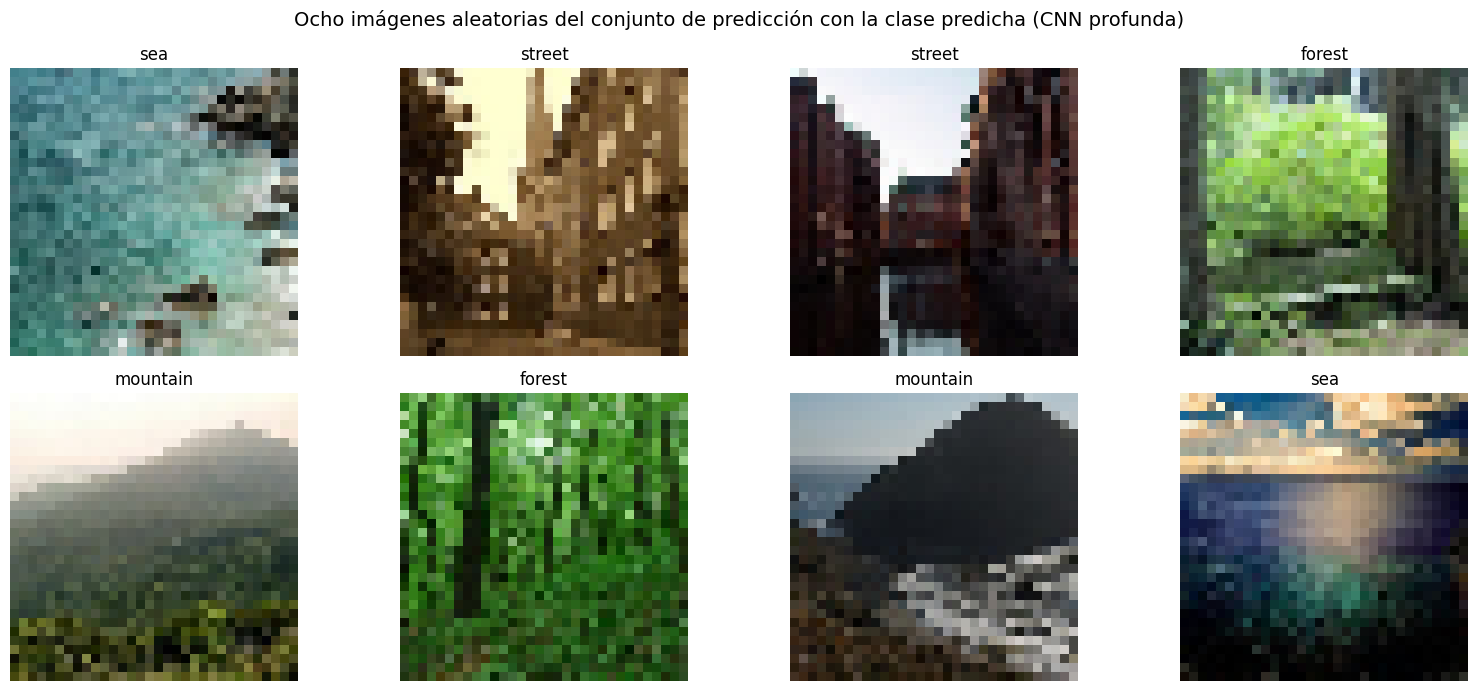

In [ ]:
proba_pred2 = modelo_cnn2.predict(X_pred, verbose=0, batch_size=128)
proba_pred1 = modelo_cnn1.predict(X_pred, verbose=0, batch_size=128)
etiq_pred2 = np.array(NOMBRES)[proba_pred2.argmax(axis=1)]
etiq_pred1 = np.array(NOMBRES)[proba_pred1.argmax(axis=1)]

resumen_pred = pd.DataFrame({
    'CNN profunda': pd.Series(etiq_pred2).value_counts(normalize=True),
    'CNN 3 conv': pd.Series(etiq_pred1).value_counts(normalize=True),
    'Distribución en train': pd.Series(y_train).value_counts(normalize=True)
}).fillna(0).round(3)
print('Distribución de clases predichas en el conjunto de predicción:')
print(resumen_pred)
print(f'\nConfianza media (probabilidad máxima) - CNN profunda: {proba_pred2.max(axis=1).mean():.3f} '
      f'| CNN 3 conv: {proba_pred1.max(axis=1).mean():.3f}')
print(f'Acuerdo entre ambas CNN: {(etiq_pred1 == etiq_pred2).mean():.3f}')

ruta_pred_y = os.path.join(CARPETA_LOCAL, 'cnn_pred_y.npy')
if os.path.exists(ruta_pred_y):
    y_pred_real = a_nombre(np.load(ruta_pred_y, allow_pickle=True).reshape(-1))
    print('Accuracy en predicción - CNN profunda:', round(accuracy_score(y_pred_real, etiq_pred2), 4),
          '| CNN 3 conv:', round(accuracy_score(y_pred_real, etiq_pred1), 4))

mostrar_imagenes(X_pred, etiq_pred2, 'Ocho imágenes aleatorias del conjunto de predicción con la clase predicha (CNN profunda)', semilla=7)

**Observación:** el conjunto de predicción no tiene etiquetas, por lo que no puede calcularse su accuracy. La CNN profunda predice una distribución de clases muy cercana a la del entrenamiento (diferencias de hasta ±2 puntos), mientras la primera CNN sobre-predice buildings y glacier y sub-predice mountain, replicando los sesgos observados en test. La primera CNN es más confiada (0.946) que la profunda (0.858) pese a ser menos precisa, un síntoma de sobreajuste; la confianza de la CNN profunda es coherente con su accuracy en test (0.838). Ambos modelos coinciden en el 76.3% de las imágenes.

## Conclusiones

**Datos.** 14.034 imágenes de entrenamiento, 3.000 de test y 7.301 de predicción (sin etiquetas), todas de 32×32 píxeles RGB. Las seis clases están razonablemente balanceadas (entre 2.191 y 2.512 imágenes por clase en entrenamiento).

**Comparación de modelos (conjunto de test):**

| Modelo | Parámetros | Accuracy test | F1 macro | Accuracy train | Brecha train-test |
|---|---|---|---|---|---|
| Fully Connected (5 capas ocultas) | 834.278 | 0.592 | 0.585 | 0.682 | 0.091 |
| CNN (3 conv + 2 densas) | 4.599.046 | 0.747 | 0.750 | 0.966 | 0.220 |
| CNN profunda (13 conv + 3 densas) | 3.785.958 | **0.838** | **0.839** | 0.892 | **0.053** |

1. **Las convoluciones son decisivas para imágenes.** La red Fully Connected, que trata cada píxel como una variable independiente, alcanza solo 59.2% de accuracy. La primera CNN sube a 74.7% (+15.5 puntos), porque sus filtros aprovechan la estructura espacial y comparten parámetros a lo largo de la imagen.
2. **La primera CNN sobreajusta fuertemente.** Su mejor desempeño en test ocurre en la época 5 (pérdida 0.64, accuracy 78.7%); desde ahí la pérdida de test crece hasta 1.62 mientras el accuracy de entrenamiento llega a 98.8%. Con 25 épocas fijas y sin regularización, el modelo memoriza el entrenamiento: brecha de 22 puntos.
3. **La CNN profunda mejora la generalización**, con más precisión y menos parámetros que la anterior: 83.8% de accuracy en test (+9.2 puntos) y una brecha de solo 5.3 puntos (vs 22.0). Lo explican las técnicas incorporadas: Batch Normalization (permite entrenar eficientemente una red de 16 capas, como advierte la guía), data augmentation, Global Average Pooling en lugar de Flatten, Dropout, reducción adaptativa del learning rate y parada temprana. Confirma lo que plantea la guía: una red más profunda aprovecha su mayor capacidad solo si se aplican métodos para entrenarla adecuadamente.

**Clase con más errores: glacier.** El mejor modelo se equivoca en el 25.7% de las imágenes de glaciares, y la confusión más frecuente es **glacier → mountain (83 casos)**. Es esperable: los glaciares suelen estar en montañas y comparten colores (blanco, gris, azul) y texturas, diferencias que se pierden con imágenes de solo 32×32 píxeles. Le siguen buildings (19.9%) y mountain (19.6%). La clase más fácil es forest (4.6% de error), por su textura verde muy característica.

**Conjunto de predicción.** Al no tener etiquetas, su rendimiento no puede medirse directamente; la comparación válida entre modelos es la de test. Aun así, el análisis es coherente con ella:
- La distribución de clases predichas por la CNN profunda es muy similar a la del entrenamiento (todas las clases dentro de ±2 puntos), mientras la primera CNN sobre-predice buildings (19.8% vs 15.6%) y glacier (19.6% vs 17.1%) y sub-predice mountain (14.2% vs 17.9%), los mismos sesgos que muestra en test (baja precision en buildings y bajo recall en mountain).
- La primera CNN es **más confiada** (probabilidad máxima media de 0.946) pese a ser menos precisa: es un síntoma típico del sobreajuste. La CNN profunda tiene una confianza media de 0.858, consistente con su accuracy real (0.838), es decir, está mejor calibrada.
- Ambas CNN coinciden en el 76.3% de las imágenes de predicción.

**Limitaciones y mejoras posibles.** La baja resolución (32×32) limita la distinción entre clases visualmente similares (glacier/mountain, buildings/street). La red Fully Connected no había convergido a las 30 épocas (su pérdida de validación seguía bajando). Usar transferencia de aprendizaje desde redes preentrenadas (por ejemplo, VGG-16 o ResNet) o imágenes de mayor resolución probablemente mejoraría los resultados.